# Experiments 014 and 015: 7B supervised controls

This notebook checks the completed 7B MC-SFT controls from both starting points:

- **014:** base model to MMLU MC-SFT, three seeds
- **015:** GSM8K-SFT checkpoint to MMLU MC-SFT, three downstream seeds

The main comparison reuses the matched 013 GRPO results. The registered expectation was about 0.80 overall with less than 1 percentage point between supervised seeds, but only 0.57 to 0.59 on the hard tier. The 013 GRPO hard-tier range was 0.639 to 0.657.

All paired tests below use matched seed-0 predictions. Seed ranges are shown separately because item-level intervals do not measure variation between training runs.

In [1]:
# load the six completed supervised runs and the matched 013 references
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '014_015_1'
FIG.mkdir(parents=True, exist_ok=True)

RUNS = {
    'base MC-SFT': {
        seed: RES / f'014_p8_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in (0, 1, 2)
    },
    'GSM8K-SFT + MC-SFT': {
        seed: RES / f'015_wsft_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in (0, 1, 2)
    },
}
GRPO_RUNS = {
    'base + GRPO': {
        0: RES / '013_COLAB_FULL_B7_base_grpo_seed0',
    },
    'GSM8K-SFT + GRPO': {
        seed: RES / f'013_COLAB_FULL_B7_sft_grpo_seed{seed}'
        for seed in (0, 1)
    },
}
BASE13 = RES / 'base_evals' / '013_COLAB_FULL_B7'

TIERS = ['easy', 'medium', 'hard']
GROUPS = TIERS + ['overall']
TIER_LOOKUP = {
    subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects
}
SUBJECTS = [subject for tier in TIERS for subject in VALIDATED_TIERS[tier]]

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {
    'base': '#4C78A8',
    'base MC-SFT': '#54A24B',
    'GSM8K-SFT + MC-SFT': '#B279A2',
    'base + GRPO': '#72B7B2',
    'GSM8K-SFT + GRPO': '#F58518',
    'probe': '#9D9DA1',
}
TIER_COLORS = {
    'easy': '#59A14F',
    'medium': '#F28E2B',
    'hard': '#E15759',
    'overall': '#4C4C4C',
}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [{**row, 'tier': TIER_LOOKUP[row['subject']]} for row in rows]

def raw_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def group_rows(rows, group):
    return rows if group == 'overall' else [
        row for row in rows if row['tier'] == group
    ]

def group_accuracy(rows, group):
    return accuracy(group_rows(rows, group))

def nonfinite_paths(value, path='root'):
    found = []
    if isinstance(value, dict):
        for key, item in value.items():
            found.extend(nonfinite_paths(item, f'{path}/{key}'))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.extend(nonfinite_paths(item, f'{path}/{index}'))
    elif isinstance(value, float) and not math.isfinite(value):
        found.append(path)
    return found

def paired_correct(rows_a, rows_b, group='overall'):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    if group != 'overall':
        rows_a = [row for row in rows_a if row['tier'] == group]
        rows_b = [row for row in rows_b if row['tier'] == group]
    return (
        [bool(row['correct']) for row in rows_a],
        [bool(row['correct']) for row in rows_b],
    )

def paired_stats(rows_a, rows_b, seed):
    output = []
    for index, group in enumerate(GROUPS):
        correct_a, correct_b = paired_correct(rows_a, rows_b, group)
        delta, lo, hi = paired_delta_ci(
            correct_a,
            correct_b,
            seed=seed + index,
        )
        a_only = sum(a and not b for a, b in zip(correct_a, correct_b))
        b_only = sum((not a) and b for a, b in zip(correct_a, correct_b))
        output.append({
            'group': group,
            'delta': delta,
            'ci_lo': lo,
            'ci_hi': hi,
            'reference_only_correct': a_only,
            'comparison_only_correct': b_only,
            'mcnemar_p': mcnemar_exact(a_only, b_only),
        })
    adjusted = holm([row['mcnemar_p'] for row in output[:3]])
    for row, value in zip(output[:3], adjusted):
        row['holm_p_tiers'] = value
    output[-1]['holm_p_tiers'] = np.nan
    return output

def load_sft_run(path):
    return {
        'train': jload(path / 'sft_trainlog.json'),
        'eval': jload(path / 'sft_eval.json'),
        'probe': jload(path / 'sft_logprob.json'),
        'preds': jsonl(path / 'sft_preds.jsonl'),
        'probe_preds': jsonl(path / 'sft_logprob_preds.jsonl'),
        'manifest': jload(path / 'manifest.json'),
        'eval_manifest': jload(path / 'sft_eval_manifest.json'),
        'summary': jload(path / 'summary.json'),
        'log': (path / 'run.log').read_text(),
    }

def load_grpo_run(path):
    return {
        'eval': jload(path / 'grpo_eval.json'),
        'probe': jload(path / 'grpo_logprob.json'),
        'preds': jsonl(path / 'grpo_preds.jsonl'),
        'probe_preds': jsonl(path / 'grpo_logprob_preds.jsonl'),
        'manifest': jload(path / 'manifest.json'),
        'summary': jload(path / 'summary.json'),
    }

SFT = {
    condition: {
        seed: load_sft_run(path)
        for seed, path in paths.items()
    }
    for condition, paths in RUNS.items()
}
GRPO = {
    condition: {
        seed: load_grpo_run(path)
        for seed, path in paths.items()
    }
    for condition, paths in GRPO_RUNS.items()
}
BASE = {
    'eval': jload(BASE13 / 'base_eval.json'),
    'probe': jload(BASE13 / 'base_logprob.json'),
    'preds': jsonl(BASE13 / 'base_preds.jsonl'),
    'probe_preds': jsonl(BASE13 / 'base_logprob_preds.jsonl'),
}

print('loaded phase 3 results')
print('figures ->', FIG)

loaded phase 3 results
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/014_015_1


## 1. Completion and run health

The checks cover step counts, both evaluation files, hardware, precision, fallback settings, git state, non-finite values and common interruption markers.

In [2]:
# verify every supervised run before using its results
health_rows = []
bad_terms = ['traceback', 'out of memory', 'protocol abort', 'keyboardinterrupt']

for condition, runs in SFT.items():
    for seed, data in runs.items():
        step_rows = [row for row in data['train'] if 'loss' in row and 'step' in row]
        manifest = data['manifest']
        eval_manifest = data['eval_manifest']
        invalid = nonfinite_paths(data['train'])
        invalid += nonfinite_paths(data['eval'])
        invalid += nonfinite_paths(data['probe'])

        assert len(step_rows) == 123
        assert max(row['step'] for row in step_rows) == 123
        assert data['eval']['n_items'] == 1884
        assert data['probe']['n_items'] == 1884
        assert len(data['preds']) == 1884
        assert len(data['probe_preds']) == 1884
        assert eval_manifest['completed'] is True
        assert eval_manifest['seed_override'] == seed
        assert manifest['model_id'] == 'Qwen/Qwen2.5-7B'
        assert manifest['resolved_dtype'] == 'bfloat16'
        assert 'A100-SXM4-80GB' in manifest['gpu']['device']
        assert manifest['config']['exec']['allow_oom_fallback'] is False
        assert manifest['git']['dirty'] is False
        assert not invalid
        assert not any(term in data['log'].lower() for term in bad_terms)

        health_rows.append({
            'condition': condition,
            'seed': seed,
            'SFT steps': len(step_rows),
            'generative items': data['eval']['n_items'],
            'probe items': data['probe']['n_items'],
            'format compliance': data['eval']['format_compliance'],
            'non-finite values': len(invalid),
            'peak VRAM GB': manifest['gpu']['peak_vram_gb'],
            'train minutes': manifest['timings_sec']['sft_train'] / 60,
            'eval minutes': eval_manifest['timings_sec']['sft_eval'] / 60,
            'git commit': manifest['git']['commit'][:8],
        })

health_tbl = pd.DataFrame(health_rows).set_index(['condition', 'seed'])
display(health_tbl.round(3))
print('all six runs passed the completion checks')

SFT steps  generative items  probe items  \
condition          seed                                             
base MC-SFT        0           123              1884         1884   
                   1           123              1884         1884   
                   2           123              1884         1884   
GSM8K-SFT + MC-SFT 0           123              1884         1884   
                   1           123              1884         1884   
                   2           123              1884         1884   

                         format compliance  non-finite values  peak VRAM GB  \
condition          seed                                                       
base MC-SFT        0                   1.0                  0        30.721   
                   1                   1.0                  0        33.301   
                   2                   1.0                  0        33.301   
GSM8K-SFT + MC-SFT 0                   1.0                  0        26.785   
                   1                   1.0                  0        26.785   
                   2                   1.0                  0        26.785   

                         train minutes  eval minutes git commit  
condition          seed                                          
base MC-SFT        0             3.139         5.503   b56a9980  
                   1             3.259         5.531   b56a9980  
                   2             3.234         5.501   b56a9980  
GSM8K-SFT + MC-SFT 0             4.495         5.688   b56a9980  
                   1             3.230         5.588   b56a9980  
                   2             3.212         5.622   b56a9980

all six runs passed the completion checks


## 2. Supervised training behaviour

saved fig01_supervised_training


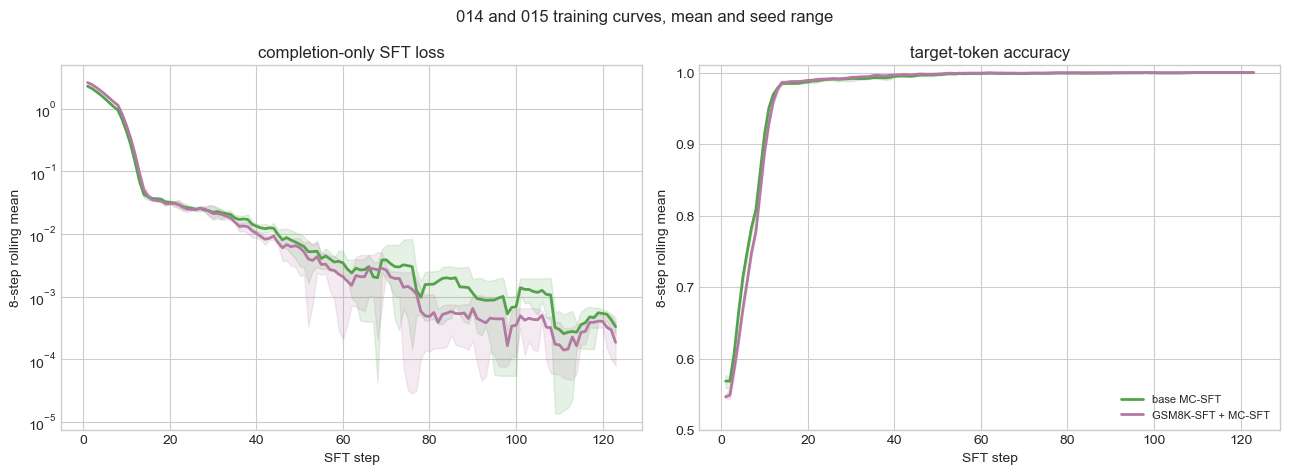

In [3]:
# compare the loss and token accuracy curves across the three seeds
train_rows = []
for condition, runs in SFT.items():
    for seed, data in runs.items():
        for row in data['train']:
            if 'loss' not in row or 'step' not in row:
                continue
            train_rows.append({
                'condition': condition,
                'seed': seed,
                'step': row['step'],
                'loss': row['loss'],
                'token accuracy': row['mean_token_accuracy'],
            })
train_tbl = pd.DataFrame(train_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for condition in RUNS:
    subset = train_tbl[train_tbl['condition'] == condition]
    for metric, ax in [('loss', axes[0]), ('token accuracy', axes[1])]:
        pivot = subset.pivot(index='step', columns='seed', values=metric)
        smooth = pivot.rolling(8, min_periods=1).mean()
        mean = smooth.mean(axis=1)
        low = smooth.min(axis=1)
        high = smooth.max(axis=1)
        ax.plot(
            mean.index,
            mean,
            color=COLORS[condition],
            lw=2,
            label=condition,
        )
        ax.fill_between(
            mean.index,
            low,
            high,
            color=COLORS[condition],
            alpha=0.15,
        )

axes[0].set_yscale('log')
axes[0].set_ylabel('8-step rolling mean')
axes[0].set_title('completion-only SFT loss')
axes[1].set_ylim(0.5, 1.01)
axes[1].set_ylabel('8-step rolling mean')
axes[1].set_title('target-token accuracy')
for ax in axes:
    ax.set_xlabel('SFT step')
axes[1].legend(fontsize=8, loc='lower right')
fig.suptitle('014 and 015 training curves, mean and seed range')
fig.tight_layout()
save(fig, 'fig01_supervised_training')
plt.show()

## 3. Primary 7B endpoint

Points are individual training seeds. Short horizontal lines show the mean. The supervised seed range is the main stability check.

mean     min     max   range  n seeds
condition          group                                           
base MC-SFT        overall  0.7836  0.7803  0.7861  0.0058        3
                   hard     0.5513  0.5429  0.5581  0.0152        3
GSM8K-SFT + MC-SFT overall  0.7767  0.7739  0.7797  0.0058        3
                   hard     0.5320  0.5177  0.5480  0.0303        3
base + GRPO        overall  0.7988  0.7988  0.7988  0.0000        1
                   hard     0.6540  0.6540  0.6540  0.0000        1
GSM8K-SFT + GRPO   overall  0.8036  0.8020  0.8052  0.0032        2
                   hard     0.6477  0.6389  0.6566  0.0177        2

saved fig02_primary_7b_endpoint


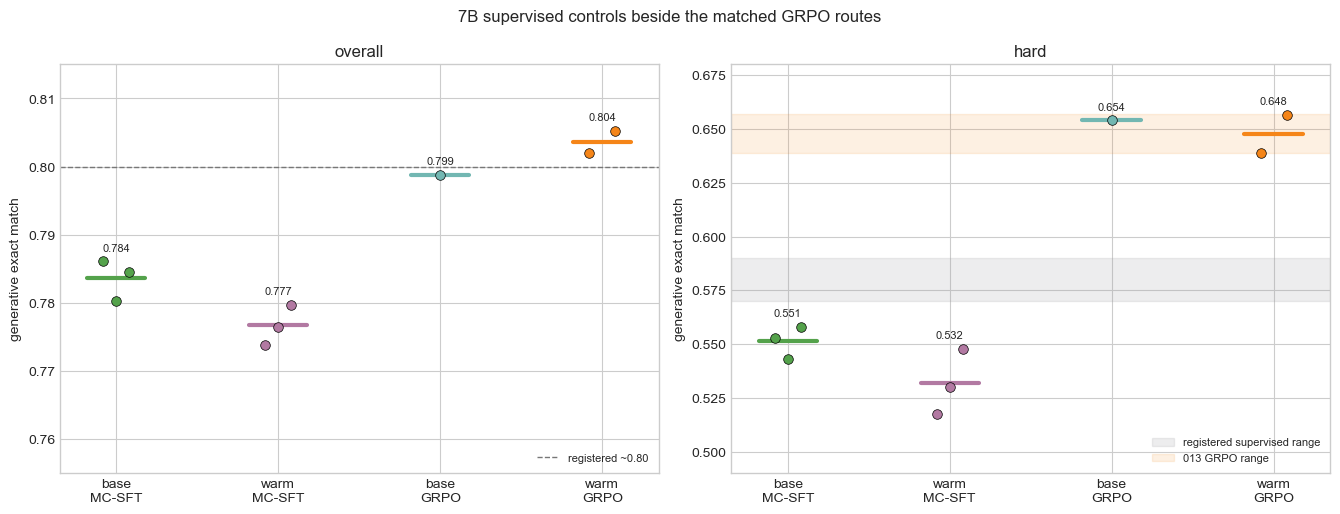

In [4]:
# collect the four completed 7B routes on the same generative test set
route_rows = []
for condition, runs in SFT.items():
    for seed, data in runs.items():
        for group in GROUPS:
            route_rows.append({
                'condition': condition,
                'seed': seed,
                'group': group,
                'accuracy': group_accuracy(data['preds'], group),
                'method': 'MC-SFT',
            })
for condition, runs in GRPO.items():
    for seed, data in runs.items():
        for group in GROUPS:
            route_rows.append({
                'condition': condition,
                'seed': seed,
                'group': group,
                'accuracy': group_accuracy(data['preds'], group),
                'method': 'GRPO',
            })
route_tbl = pd.DataFrame(route_rows)
route_order = [
    'base MC-SFT',
    'GSM8K-SFT + MC-SFT',
    'base + GRPO',
    'GSM8K-SFT + GRPO',
]

summary_rows = []
for (condition, group), values in route_tbl.groupby(['condition', 'group']):
    scores = values['accuracy'].to_numpy()
    summary_rows.append({
        'condition': condition,
        'group': group,
        'mean': scores.mean(),
        'min': scores.min(),
        'max': scores.max(),
        'range': scores.max() - scores.min(),
        'n seeds': len(scores),
    })
endpoint_tbl = pd.DataFrame(summary_rows).set_index(['condition', 'group'])
display(endpoint_tbl.loc[
    pd.IndexSlice[route_order, ['overall', 'hard']],
    :
].round(4))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for ax, group, ylim in [
    (axes[0], 'overall', (0.755, 0.815)),
    (axes[1], 'hard', (0.49, 0.68)),
]:
    for position, condition in enumerate(route_order):
        scores = route_tbl.query(
            'condition == @condition and group == @group'
        )['accuracy'].to_numpy()
        offsets = np.linspace(-0.08, 0.08, len(scores)) if len(scores) > 1 else [0]
        ax.scatter(
            position + np.asarray(offsets),
            scores,
            color=COLORS[condition],
            edgecolor='black',
            linewidth=0.5,
            s=48,
            zorder=3,
        )
        mean = scores.mean()
        ax.plot(
            [position - 0.18, position + 0.18],
            [mean, mean],
            color=COLORS[condition],
            lw=3,
        )
        ax.annotate(f'{mean:.3f}', (position, scores.max()), xytext=(0, 6),
                    textcoords='offset points', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(range(len(route_order)))
    ax.set_xticklabels(
        ['base\nMC-SFT', 'warm\nMC-SFT', 'base\nGRPO', 'warm\nGRPO']
    )
    ax.set_ylim(*ylim)
    ax.set_ylabel('generative exact match')
    ax.set_title(group)

axes[0].axhline(0.80, color='#777777', lw=1, ls='--', label='registered ~0.80')
axes[0].legend(fontsize=8, loc='lower right')
axes[1].axhspan(0.57, 0.59, color='#9D9DA1', alpha=0.18, label='registered supervised range')
axes[1].axhspan(0.639, 0.657, color=COLORS['GSM8K-SFT + GRPO'], alpha=0.12, label='013 GRPO range')
axes[1].legend(fontsize=8, loc='lower right')
fig.suptitle('7B supervised controls beside the matched GRPO routes')
fig.tight_layout()
save(fig, 'fig02_primary_7b_endpoint')
plt.show()

saved fig03_tier_profiles


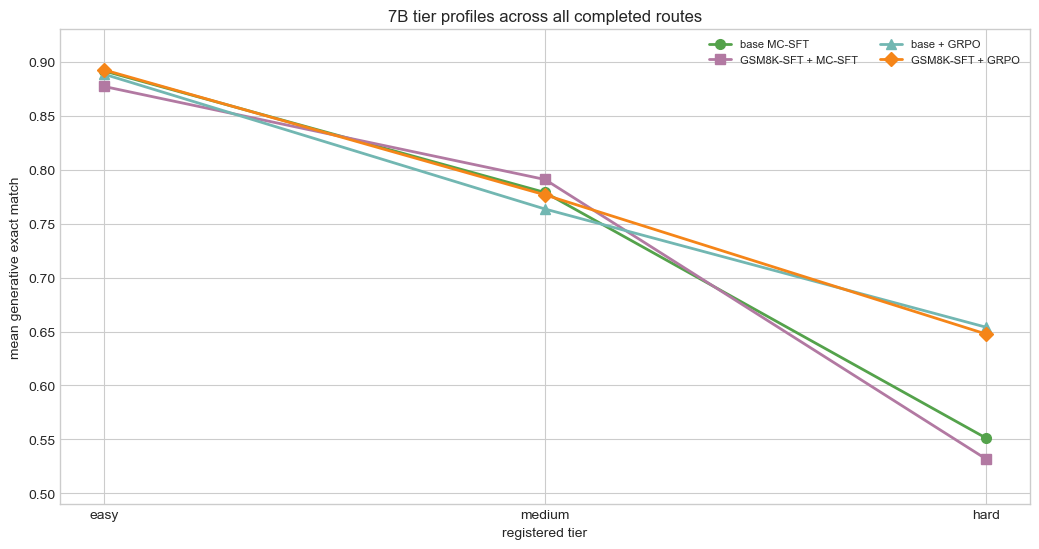

In [5]:
# show how the four routes separate across the registered tiers
fig, ax = plt.subplots(figsize=(10.5, 5.6))
markers = ['o', 's', '^', 'D']
for condition, marker in zip(route_order, markers):
    values = [
        endpoint_tbl.loc[(condition, tier), 'mean']
        for tier in TIERS
    ]
    ax.plot(
        TIERS,
        values,
        marker=marker,
        markersize=7,
        color=COLORS[condition],
        lw=2,
        label=condition,
    )
ax.set_ylim(0.49, 0.93)
ax.set_ylabel('mean generative exact match')
ax.set_xlabel('registered tier')
ax.set_title('7B tier profiles across all completed routes')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, 'fig03_tier_profiles')
plt.show()

## 4. Matched item-level comparisons

These are exploratory seed-0 comparisons on the same 1,884 test items. The interval is a paired bootstrap interval. McNemar tests are included in the exact table, with Holm adjustment across the three registered tiers.

delta     ci_lo     ci_hi  reference_only_correct  \
start           group                                                           
base start      easy    -0.006826 -0.025028  0.011377                      37   
                medium  -0.016420 -0.044335  0.011494                      43   
                hard     0.101010  0.045455  0.159091                      53   
                overall  0.012739 -0.004777  0.030255                     133   
GSM8K-SFT start easy     0.019340  0.001138  0.037543                      24   
                medium  -0.019704 -0.045977  0.006568                      40   
                hard     0.121212  0.065657  0.176768                      43   
                overall  0.028132  0.011146  0.045117                     107   

                         comparison_only_correct  mcnemar_p  holm_p_tiers  
start           group                                                      
base start      easy                          31   0.544612      0.603745  
                medium                        33   0.301872      0.603745  
                hard                          93   0.001173      0.003518  
                overall                      157   0.176719           NaN  
GSM8K-SFT start easy                          41   0.046353      0.092707  
                medium                        28   0.181810      0.181810  
                hard                          91   0.000041      0.000123  
                overall                      160   0.001415           NaN

saved fig04_paired_method_effects


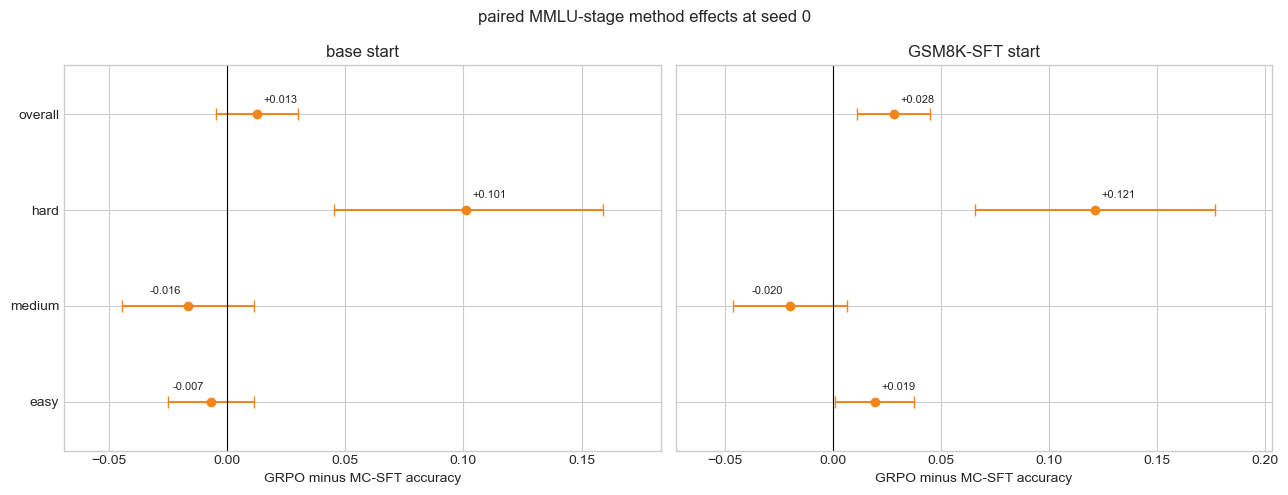

In [6]:
# estimate the MMLU-stage method effect after each starting point
METHOD_COMPARISONS = {
    'base start': paired_stats(
        SFT['base MC-SFT'][0]['preds'],
        GRPO['base + GRPO'][0]['preds'],
        seed=2100,
    ),
    'GSM8K-SFT start': paired_stats(
        SFT['GSM8K-SFT + MC-SFT'][0]['preds'],
        GRPO['GSM8K-SFT + GRPO'][0]['preds'],
        seed=2200,
    ),
}
method_stats_tbl = pd.concat(
    [
        pd.DataFrame(rows).assign(start=label)
        for label, rows in METHOD_COMPARISONS.items()
    ],
    ignore_index=True,
).set_index(['start', 'group'])
display(method_stats_tbl.round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (label, rows) in zip(axes, METHOD_COMPARISONS.items()):
    table = pd.DataFrame(rows).set_index('group').loc[GROUPS]
    y = np.arange(len(GROUPS))
    values = table['delta'].to_numpy()
    errors = [
        values - table['ci_lo'].to_numpy(),
        table['ci_hi'].to_numpy() - values,
    ]
    ax.errorbar(
        values,
        y,
        xerr=errors,
        fmt='o',
        capsize=4,
        color=COLORS['GSM8K-SFT + GRPO'],
    )
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(GROUPS)
    ax.invert_yaxis()
    ax.set_xlabel('GRPO minus MC-SFT accuracy')
    ax.set_title(label)
    ax.margins(x=0.12, y=0.17)
    for position, value in zip(y, values):
        ax.annotate(f'{value:+.3f}', (value, position), xytext=(5 if value >= 0 else -5, 7),
                    textcoords='offset points', ha='left' if value >= 0 else 'right',
                    va='bottom', fontsize=8)
fig.suptitle('paired MMLU-stage method effects at seed 0')
fig.tight_layout()
save(fig, 'fig04_paired_method_effects')
plt.show()

delta     ci_lo     ci_hi  reference_only_correct  \
method          group                                                           
MC-SFT endpoint easy    -0.021615 -0.034158 -0.009101                      26   
                medium   0.016420  0.001642  0.031199                       6   
                hard    -0.035354 -0.068182 -0.002525                      29   
                overall -0.012208 -0.022824 -0.002123                      61   
GRPO endpoint   easy     0.004551 -0.012514  0.021615                      29   
                medium   0.013136 -0.016420  0.044335                      40   
                hard    -0.015152 -0.068182  0.037879                      63   
                overall  0.003185 -0.013270  0.020170                     132   

                         comparison_only_correct  mcnemar_p  holm_p_tiers  
method          group                                                      
MC-SFT endpoint easy                           7   0.001319      0.003956  
                medium                        16   0.052479      0.097534  
                hard                          15   0.048767      0.097534  
                overall                       38   0.026525           NaN  
GRPO endpoint   easy                          33   0.703537      1.000000  
                medium                        48   0.455741      1.000000  
                hard                          57   0.648260      1.000000  
                overall                      138   0.760972           NaN

saved fig05_paired_preparation_effects


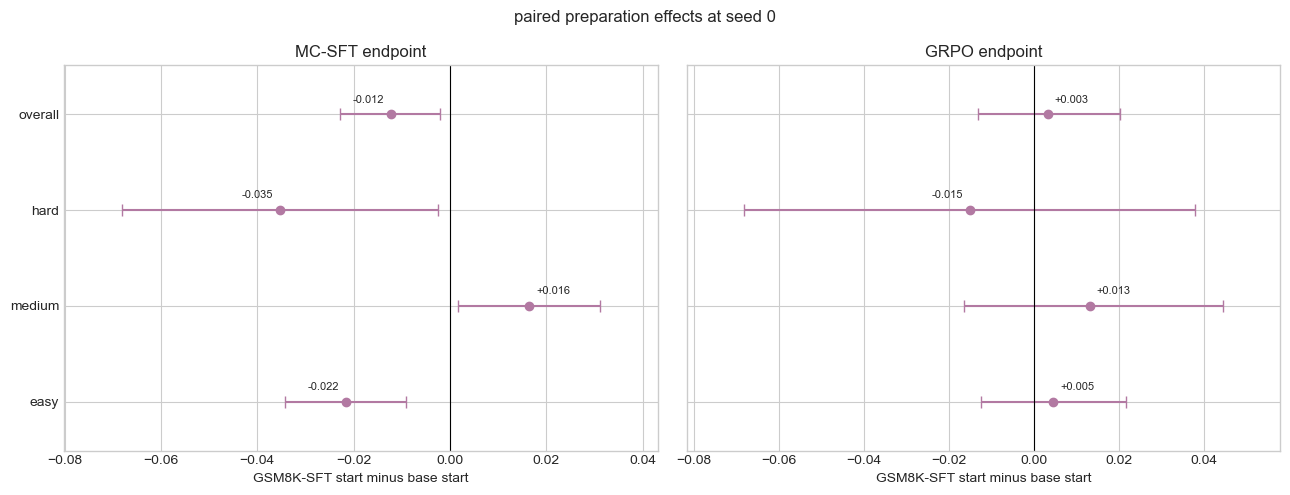

In [7]:
# compare the GSM8K warm start with the base start inside each MMLU method
PREP_COMPARISONS = {
    'MC-SFT endpoint': paired_stats(
        SFT['base MC-SFT'][0]['preds'],
        SFT['GSM8K-SFT + MC-SFT'][0]['preds'],
        seed=2300,
    ),
    'GRPO endpoint': paired_stats(
        GRPO['base + GRPO'][0]['preds'],
        GRPO['GSM8K-SFT + GRPO'][0]['preds'],
        seed=2400,
    ),
}
prep_stats_tbl = pd.concat(
    [
        pd.DataFrame(rows).assign(method=label)
        for label, rows in PREP_COMPARISONS.items()
    ],
    ignore_index=True,
).set_index(['method', 'group'])
display(prep_stats_tbl.round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (label, rows) in zip(axes, PREP_COMPARISONS.items()):
    table = pd.DataFrame(rows).set_index('group').loc[GROUPS]
    y = np.arange(len(GROUPS))
    values = table['delta'].to_numpy()
    errors = [
        values - table['ci_lo'].to_numpy(),
        table['ci_hi'].to_numpy() - values,
    ]
    ax.errorbar(
        values,
        y,
        xerr=errors,
        fmt='o',
        capsize=4,
        color=COLORS['GSM8K-SFT + MC-SFT'],
    )
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(GROUPS)
    ax.invert_yaxis()
    ax.set_xlabel('GSM8K-SFT start minus base start')
    ax.set_title(label)
    ax.margins(x=0.12, y=0.17)
    for position, value in zip(y, values):
        ax.annotate(f'{value:+.3f}', (value, position), xytext=(5 if value >= 0 else -5, 7),
                    textcoords='offset points', ha='left' if value >= 0 else 'right',
                    va='bottom', fontsize=8)
fig.suptitle('paired preparation effects at seed 0')
fig.tight_layout()
save(fig, 'fig05_paired_preparation_effects')
plt.show()

## 5. Subject pattern

,tier,base start,GSM8K-SFT start
subject,,,
high_school_psychology,easy,0.0055,0.0257
marketing,easy,-0.0256,-0.0299
us_foreign_policy,easy,-0.0300,0.1000
high_school_geography,medium,0.0000,-0.0101
philosophy,medium,-0.0257,-0.0096
business_ethics,medium,-0.0200,-0.0700
high_school_mathematics,hard,0.1556,0.1963
formal_logic,hard,-0.0159,-0.0397


saved fig06_subject_method_differences


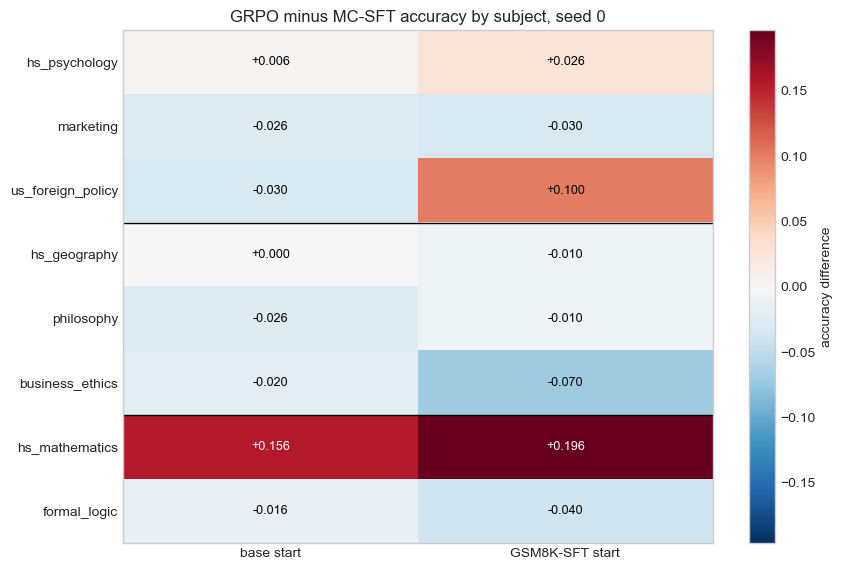

In [8]:
# locate the seed-0 method difference inside each MMLU subject
subject_rows = []
for subject in SUBJECTS:
    subject_rows.append({
        'subject': subject,
        'tier': TIER_LOOKUP[subject],
        'base start': (
            GRPO['base + GRPO'][0]['eval']['per_subject_acc'][subject]
            - SFT['base MC-SFT'][0]['eval']['per_subject_acc'][subject]
        ),
        'GSM8K-SFT start': (
            GRPO['GSM8K-SFT + GRPO'][0]['eval']['per_subject_acc'][subject]
            - SFT['GSM8K-SFT + MC-SFT'][0]['eval']['per_subject_acc'][subject]
        ),
    })
subject_tbl = pd.DataFrame(subject_rows).set_index('subject')
display(subject_tbl.round(4))

heat_cols = ['base start', 'GSM8K-SFT start']
values = subject_tbl[heat_cols].to_numpy()
limit = max(abs(values.min()), abs(values.max()))
fig, ax = plt.subplots(figsize=(8.8, 5.8))
image = ax.imshow(
    values,
    cmap='RdBu_r',
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    aspect='auto',
    interpolation='nearest',
)
ax.grid(False)
for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        color = heatmap_text_color(image, values[row, col])
        ax.text(col, row, f'{values[row, col]:+.3f}', ha='center', va='center', fontsize=9, color=color)
ax.set_xticks(np.arange(len(heat_cols)))
ax.set_xticklabels(['base start', 'GSM8K-SFT start'])
ax.set_yticks(np.arange(len(subject_tbl)))
ax.set_yticklabels([
    subject.replace('high_school_', 'hs_')
    for subject in subject_tbl.index
])
ax.axhline(2.5, color='black', lw=1)
ax.axhline(5.5, color='black', lw=1)
ax.set_title('GRPO minus MC-SFT accuracy by subject, seed 0')
fig.colorbar(image, ax=ax, label='accuracy difference')
fig.tight_layout()
save(fig, 'fig06_subject_method_differences')
plt.show()

## 6. Probe and output behaviour

The letter probe is kept separate from free generation. A stable probe with a changed generative score is evidence about elicitation under this protocol, not proof that factual knowledge was created or removed.

,generative accuracy,letter-probe accuracy,format compliance,mean response length,extraction failure
condition,,,,,
base,0.7686,0.8004,0.3493,194.0748,0.0271
base MC-SFT s0,0.7861,0.7999,1.0000,16.0000,0.0000
base MC-SFT s1,0.7803,0.8025,1.0000,16.0000,0.0000
base MC-SFT s2,0.7845,0.7999,1.0000,15.9952,0.0000
GSM8K-SFT + MC-SFT s0,0.7739,0.8025,1.0000,16.0000,0.0000
GSM8K-SFT + MC-SFT s1,0.7765,0.8004,1.0000,16.0000,0.0000
GSM8K-SFT + MC-SFT s2,0.7797,0.7994,1.0000,16.0000,0.0000
base + GRPO s0,0.7988,0.7999,0.9766,115.0743,0.0159
GSM8K-SFT + GRPO s0,0.8020,0.7999,0.9841,66.4512,0.0117


saved fig07_eval_diagnostics


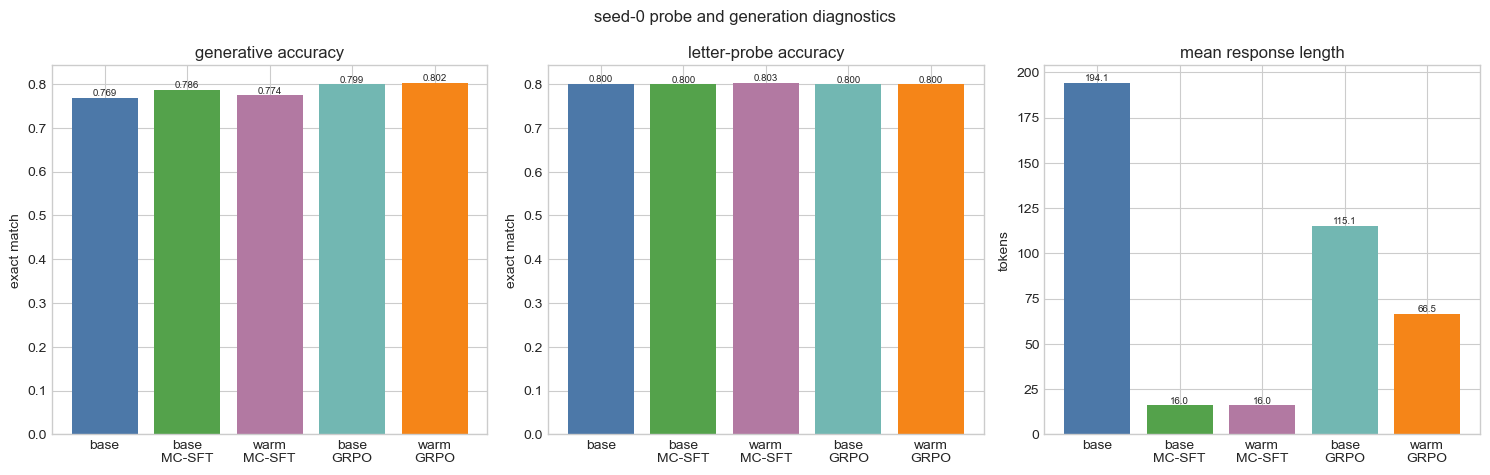

In [9]:
# compare free generation, letter probes and output behaviour
diagnostic_rows = [{
    'condition': 'base',
    'generative accuracy': accuracy(BASE['preds']),
    'letter-probe accuracy': accuracy(BASE['probe_preds']),
    'format compliance': BASE['eval']['format_compliance'],
    'mean response length': BASE['eval']['mean_len'],
    'extraction failure': BASE['eval']['extraction_failure_rate'],
}]
for condition, runs in SFT.items():
    for seed, data in runs.items():
        diagnostic_rows.append({
            'condition': f'{condition} s{seed}',
            'generative accuracy': accuracy(data['preds']),
            'letter-probe accuracy': accuracy(data['probe_preds']),
            'format compliance': data['eval']['format_compliance'],
            'mean response length': data['eval']['mean_len'],
            'extraction failure': data['eval']['extraction_failure_rate'],
        })
for condition, runs in GRPO.items():
    for seed, data in runs.items():
        diagnostic_rows.append({
            'condition': f'{condition} s{seed}',
            'generative accuracy': accuracy(data['preds']),
            'letter-probe accuracy': accuracy(data['probe_preds']),
            'format compliance': data['eval']['format_compliance'],
            'mean response length': data['eval']['mean_len'],
            'extraction failure': data['eval']['extraction_failure_rate'],
        })
diagnostics_tbl = pd.DataFrame(diagnostic_rows).set_index('condition')
display(diagnostics_tbl.round(4))

diagnostic_plot = diagnostics_tbl.loc[
    [
        'base',
        'base MC-SFT s0',
        'GSM8K-SFT + MC-SFT s0',
        'base + GRPO s0',
        'GSM8K-SFT + GRPO s0',
    ]
]
short_labels = ['base', 'base\nMC-SFT', 'warm\nMC-SFT', 'base\nGRPO', 'warm\nGRPO']
bar_colors = [
    COLORS['base'],
    COLORS['base MC-SFT'],
    COLORS['GSM8K-SFT + MC-SFT'],
    COLORS['base + GRPO'],
    COLORS['GSM8K-SFT + GRPO'],
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
metrics = [
    ('generative accuracy', 'exact match'),
    ('letter-probe accuracy', 'exact match'),
    ('mean response length', 'tokens'),
]
for ax, (metric, ylabel) in zip(axes, metrics):
    values = diagnostic_plot[metric].to_numpy()
    bars = ax.bar(np.arange(len(values)), values, color=bar_colors)
    for bar, value in zip(bars, values):
        label = f'{value:.1f}' if metric == 'mean response length' else f'{value:.3f}'
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            label,
            ha='center',
            va='bottom',
            fontsize=7,
        )
    ax.set_xticks(np.arange(len(values)))
    ax.set_xticklabels(short_labels)
    ax.set_ylabel(ylabel)
    ax.set_title(metric)
fig.suptitle('seed-0 probe and generation diagnostics')
fig.tight_layout()
save(fig, 'fig07_eval_diagnostics')
plt.show()

## 7. Cross-scale context

This section uses only completed A100 runs. The main comparison is the same MC-SFT control against GRPO at 0.5B, 1.5B, 3B and 7B. Base-GRPO has one seed at each scale. Warm GRPO has three seeds at 0.5B and two seeds at the other scales.

In [10]:
# gather matched supervised and GRPO endpoints from every completed A100 scale
SCALE_SPECS = {
    '0.5B': {
        'params': 0.5,
        'code': 'B05',
        'base_sft_exp': '007_p8',
        'warm_sft_exp': '008_wsft',
        'warm_grpo_exp': '006',
        'base_grpo_exp': '005',
        'warm_grpo_seeds': (0, 1, 2),
    },
    '1.5B': {
        'params': 1.5,
        'code': 'B15',
        'base_sft_exp': '010_p8',
        'warm_sft_exp': '011_wsft',
        'warm_grpo_exp': '009',
        'base_grpo_exp': '012',
        'warm_grpo_seeds': (0, 1),
    },
    '3B': {
        'params': 3.0,
        'code': 'B3',
        'base_sft_exp': '007_p8',
        'warm_sft_exp': '008_wsft',
        'warm_grpo_exp': '003',
        'base_grpo_exp': '004',
        'warm_grpo_seeds': (0, 1),
    },
    '7B': {
        'params': 7.0,
        'code': 'B7',
        'base_sft_exp': '014_p8',
        'warm_sft_exp': '015_wsft',
        'warm_grpo_exp': '013',
        'base_grpo_exp': '013',
        'warm_grpo_seeds': (0, 1),
    },
}

scale_rows = []
for scale, spec in SCALE_SPECS.items():
    route_specs = [
        ('base MC-SFT', spec['base_sft_exp'], 'sft_only', 'sft', (0, 1, 2)),
        ('GSM8K-SFT + MC-SFT', spec['warm_sft_exp'], 'sft_only', 'sft', (0, 1, 2)),
        ('base + GRPO', spec['base_grpo_exp'], 'base_grpo', 'grpo', (0,)),
        (
            'GSM8K-SFT + GRPO',
            spec['warm_grpo_exp'],
            'sft_grpo',
            'grpo',
            spec['warm_grpo_seeds'],
        ),
    ]
    for condition, experiment, route, stage, seeds in route_specs:
        for seed in seeds:
            run_tag = (
                f"{experiment}_COLAB_FULL_{spec['code']}_"
                f'{route}_seed{seed}'
            )
            run_dir = RES / run_tag
            predictions = jsonl(run_dir / f'{stage}_preds.jsonl')
            manifest = jload(run_dir / 'manifest.json')
            assert 'A100' in manifest['gpu']['device']
            scale_rows.append({
                'scale': scale,
                'params_b': spec['params'],
                'condition': condition,
                'seed': seed,
                'overall': group_accuracy(predictions, 'overall'),
                'hard': group_accuracy(predictions, 'hard'),
                'GPU': manifest['gpu']['device'],
            })

scale_seed_tbl = pd.DataFrame(scale_rows)
scale_summary_rows = []
for (scale, params, condition), values in scale_seed_tbl.groupby(
    ['scale', 'params_b', 'condition']
):
    for metric in ['overall', 'hard']:
        scores = values[metric].to_numpy()
        scale_summary_rows.append({
            'scale': scale,
            'params_b': params,
            'condition': condition,
            'metric': metric,
            'mean': scores.mean(),
            'min': scores.min(),
            'max': scores.max(),
            'n seeds': len(scores),
        })
scale_summary_tbl = pd.DataFrame(scale_summary_rows)
display(scale_summary_tbl.set_index(
    ['scale', 'condition', 'metric']
).round(4))

params_b    mean     min     max  n seeds
scale condition          metric                                            
0.5B  GSM8K-SFT + GRPO   overall       0.5  0.4278  0.3153  0.5058        3
                         hard          0.5  0.2348  0.2222  0.2449        3
      GSM8K-SFT + MC-SFT overall       0.5  0.5334  0.5318  0.5345        3
                         hard          0.5  0.3443  0.3333  0.3535        3
      base + GRPO        overall       0.5  0.3992  0.3992  0.3992        1
                         hard          0.5  0.2551  0.2551  0.2551        1
      base MC-SFT        overall       0.5  0.5340  0.5303  0.5382        3
                         hard          0.5  0.3510  0.3333  0.3712        3
1.5B  GSM8K-SFT + GRPO   overall       1.5  0.6545  0.6348  0.6741        2
                         hard          1.5  0.4217  0.3965  0.4470        2
      GSM8K-SFT + MC-SFT overall       1.5  0.6921  0.6879  0.6953        3
                         hard          1.5  0.4537  0.4470  0.4621        3
      base + GRPO        overall       1.5  0.6088  0.6088  0.6088        1
                         hard          1.5  0.4192  0.4192  0.4192        1
      base MC-SFT        overall       1.5  0.6916  0.6906  0.6927        3
                         hard          1.5  0.4478  0.4268  0.4646        3
3B    GSM8K-SFT + GRPO   overall       3.0  0.7213  0.7160  0.7266        2
                         hard          3.0  0.5354  0.5202  0.5505        2
      GSM8K-SFT + MC-SFT overall       3.0  0.7371  0.7325  0.7394        3
                         hard          3.0  0.4832  0.4697  0.5000        3
      base + GRPO        overall       3.0  0.6768  0.6768  0.6768        1
                         hard          3.0  0.5429  0.5429  0.5429        1
      base MC-SFT        overall       3.0  0.7309  0.7256  0.7346        3
                         hard          3.0  0.5000  0.4773  0.5202        3
7B    GSM8K-SFT + GRPO   overall       7.0  0.8036  0.8020  0.8052        2
                         hard          7.0  0.6477  0.6389  0.6566        2
      GSM8K-SFT + MC-SFT overall       7.0  0.7767  0.7739  0.7797        3
                         hard          7.0  0.5320  0.5177  0.5480        3
      base + GRPO        overall       7.0  0.7988  0.7988  0.7988        1
                         hard          7.0  0.6540  0.6540  0.6540        1
      base MC-SFT        overall       7.0  0.7836  0.7803  0.7861        3
                         hard          7.0  0.5513  0.5429  0.5581        3

saved fig08_cross_scale_endpoints


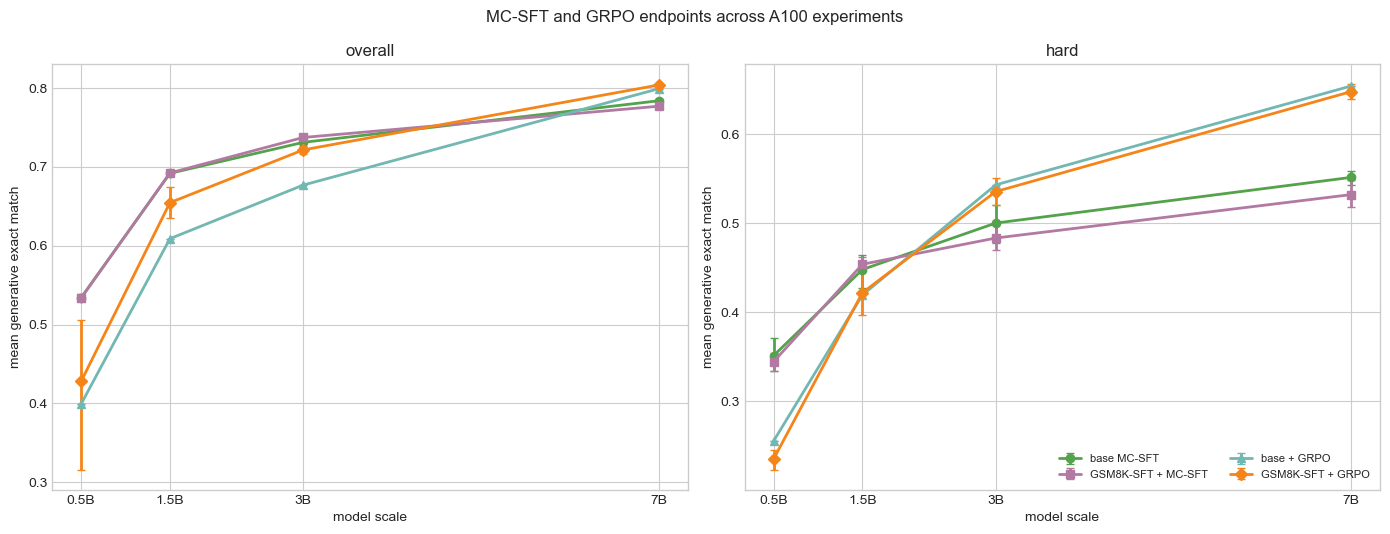

In [11]:
# compare final route levels while keeping the seed range visible
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
markers = ['o', 's', '^', 'D']
for ax, metric in zip(axes, ['overall', 'hard']):
    for condition, marker in zip(route_order, markers):
        table = scale_summary_tbl.query(
            'condition == @condition and metric == @metric'
        ).sort_values('params_b')
        x = table['params_b'].to_numpy()
        mean = table['mean'].to_numpy()
        errors = [
            mean - table['min'].to_numpy(),
            table['max'].to_numpy() - mean,
        ]
        ax.errorbar(
            x,
            mean,
            yerr=errors,
            marker=marker,
            capsize=3,
            color=COLORS[condition],
            lw=2,
            label=condition,
        )
    ax.set_xticks([0.5, 1.5, 3.0, 7.0])
    ax.set_xticklabels(['0.5B', '1.5B', '3B', '7B'])
    ax.set_xlabel('model scale')
    ax.set_ylabel('mean generative exact match')
    ax.set_title(metric)
axes[1].legend(fontsize=8, ncol=2, loc='lower right')
fig.suptitle('MC-SFT and GRPO endpoints across A100 experiments')
fig.tight_layout()
save(fig, 'fig08_cross_scale_endpoints')
plt.show()

params_b  overall    hard
scale start                                     
0.5B  base start            0.5  -0.1391 -0.1162
      GSM8K-SFT start       0.5  -0.0722 -0.1010
1.5B  base start            1.5  -0.0828 -0.0076
      GSM8K-SFT start       1.5  -0.0212  0.0000
3B    base start            3.0  -0.0557  0.0404
      GSM8K-SFT start       3.0  -0.0165  0.0505
7B    base start            7.0   0.0127  0.1010
      GSM8K-SFT start       7.0   0.0281  0.1212

saved fig09_cross_scale_method_difference


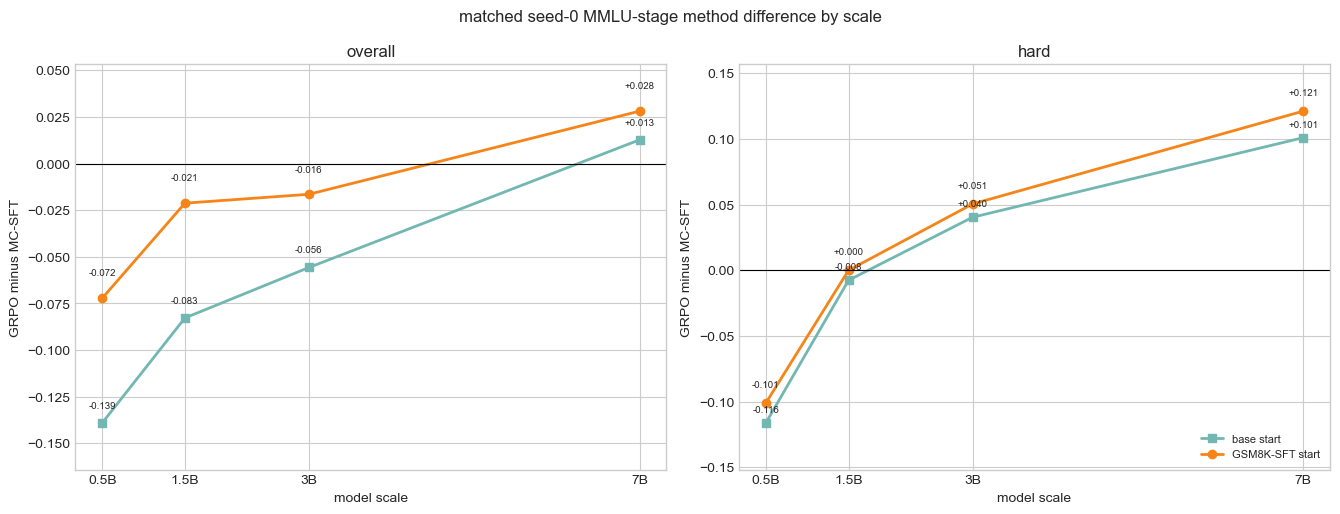

In [12]:
# isolate the seed-0 method difference at each model scale
advantage_rows = []
for scale, values in scale_seed_tbl.groupby('scale'):
    params = values['params_b'].iloc[0]
    for start, sft_condition, grpo_condition in [
        ('base start', 'base MC-SFT', 'base + GRPO'),
        (
            'GSM8K-SFT start',
            'GSM8K-SFT + MC-SFT',
            'GSM8K-SFT + GRPO',
        ),
    ]:
        sft = values.query(
            'condition == @sft_condition and seed == 0'
        ).iloc[0]
        grpo = values.query(
            'condition == @grpo_condition and seed == 0'
        ).iloc[0]
        advantage_rows.append({
            'scale': scale,
            'params_b': params,
            'start': start,
            'overall': grpo['overall'] - sft['overall'],
            'hard': grpo['hard'] - sft['hard'],
        })
advantage_tbl = pd.DataFrame(advantage_rows).sort_values('params_b')
display(advantage_tbl.set_index(['scale', 'start']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for ax, metric in zip(axes, ['overall', 'hard']):
    for start, marker, color in [
        ('base start', 's', COLORS['base + GRPO']),
        ('GSM8K-SFT start', 'o', COLORS['GSM8K-SFT + GRPO']),
    ]:
        table = advantage_tbl.query('start == @start')
        ax.plot(
            table['params_b'],
            table[metric],
            marker=marker,
            color=color,
            lw=2,
            label=start,
        )
        label_offset = 0.008 if start == 'base start' else 0.012
        for x, value in zip(table['params_b'], table[metric]):
            ax.text(
                x,
                value + label_offset,
                f'{value:+.3f}',
                ha='center',
                fontsize=7,
            )
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks([0.5, 1.5, 3.0, 7.0])
    ax.set_xticklabels(['0.5B', '1.5B', '3B', '7B'])
    ax.set_xlabel('model scale')
    ax.set_ylabel('GRPO minus MC-SFT')
    ax.set_title(metric)
    ax.margins(y=0.15)
axes[1].legend(fontsize=8, loc='lower right')
fig.suptitle('matched seed-0 MMLU-stage method difference by scale')
fig.tight_layout()
save(fig, 'fig09_cross_scale_method_difference')
plt.show()

## 8. Recorded compute

training minutes  probe minutes  \
condition          seed                                    
base MC-SFT        0                3.139          0.747   
                   1                3.259          0.711   
                   2                3.234          0.706   
GSM8K-SFT + MC-SFT 0                4.495          0.845   
                   1                3.230          0.829   
                   2                3.212          0.801   

                         generative eval minutes  peak VRAM GB  \
condition          seed                                          
base MC-SFT        0                       5.503        30.721   
                   1                       5.531        33.301   
                   2                       5.501        33.301   
GSM8K-SFT + MC-SFT 0                       5.688        26.785   
                   1                       5.588        26.785   
                   2                       5.622        26.785   

                         total recorded minutes  
condition          seed                          
base MC-SFT        0                      9.389  
                   1                      9.501  
                   2                      9.442  
GSM8K-SFT + MC-SFT 0                     11.027  
                   1                      9.647  
                   2                      9.635

saved fig10_phase3_compute


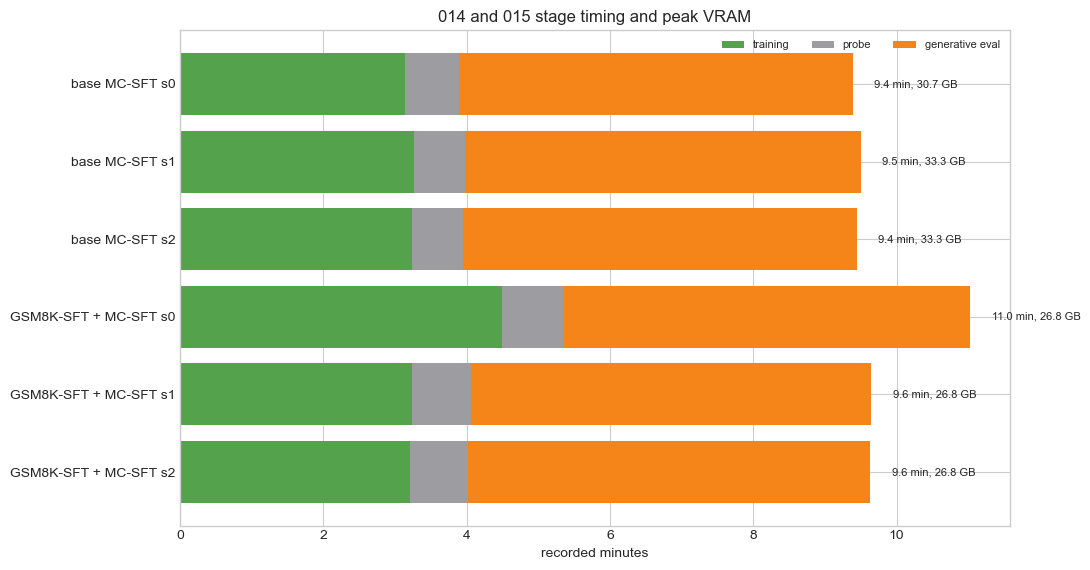

,ts_start,notebook,colab_cu_before,unit_rate,ts_end,colab_cu_after,colab_cu_used,closed_on_resume
session_id,,,,,,,,
20260723_194231,2026-07-23 19:42,014_015_colab_7b_mc_sft,103.95,6.77,2026-07-23 21:42,90.77,13.18,False


In [13]:
# separate training, probe and generative evaluation time for all six runs
compute_rows = []
for condition, runs in SFT.items():
    for seed, data in runs.items():
        timings = data['manifest']['timings_sec']
        eval_timings = data['eval_manifest']['timings_sec']
        compute_rows.append({
            'condition': condition,
            'seed': seed,
            'training minutes': timings.get('sft_train', 0) / 60,
            'probe minutes': timings.get('sft_logprob_eval', 0) / 60,
            'generative eval minutes': eval_timings.get('sft_eval', 0) / 60,
            'peak VRAM GB': data['manifest']['gpu']['peak_vram_gb'],
        })
compute_tbl = pd.DataFrame(compute_rows)
compute_tbl['total recorded minutes'] = compute_tbl[
    ['training minutes', 'probe minutes', 'generative eval minutes']
].sum(axis=1)
display(compute_tbl.set_index(['condition', 'seed']).round(3))

fig, ax = plt.subplots(figsize=(11, 5.8))
plot_tbl = compute_tbl.copy()
plot_tbl['label'] = plot_tbl.apply(
    lambda row: f"{row['condition']} s{row['seed']}",
    axis=1,
)
parts = ['training minutes', 'probe minutes', 'generative eval minutes']
part_colors = ['#54A24B', '#9D9DA1', '#F58518']
left = np.zeros(len(plot_tbl))
for part, color in zip(parts, part_colors):
    values = plot_tbl[part].to_numpy()
    ax.barh(
        np.arange(len(plot_tbl)),
        values,
        left=left,
        color=color,
        label=part.replace(' minutes', ''),
    )
    left += values
for position, row in plot_tbl.iterrows():
    ax.text(
        row['total recorded minutes'] + 0.3,
        position,
        f"{row['total recorded minutes']:.1f} min, {row['peak VRAM GB']:.1f} GB",
        va='center',
        fontsize=8,
    )
ax.set_yticks(np.arange(len(plot_tbl)))
ax.set_yticklabels(plot_tbl['label'])
ax.invert_yaxis()
ax.set_xlabel('recorded minutes')
ax.set_title('014 and 015 stage timing and peak VRAM')
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
save(fig, 'fig10_phase3_compute')
plt.show()

unit_rows = raw_jsonl(RES / 'colab_units.jsonl')
phase3_units = [
    row for row in unit_rows
    if row.get('notebook') == '014_015_colab_7b_mc_sft'
]
assert len(phase3_units) == 1
unit_tbl = pd.DataFrame(phase3_units).set_index('session_id')
display(unit_tbl)

## 9. Exact result tables

In [14]:
# keep the exact values behind the main plots in compact tables
supervised_summary = endpoint_tbl.loc[
    pd.IndexSlice[
        ['base MC-SFT', 'GSM8K-SFT + MC-SFT'],
        ['overall', 'easy', 'medium', 'hard'],
    ],
    :
]
display(supervised_summary.round(6))

prediction_check = pd.DataFrame([
    {
        'condition': condition,
        'overall mean': endpoint_tbl.loc[(condition, 'overall'), 'mean'],
        'overall seed range': endpoint_tbl.loc[(condition, 'overall'), 'range'],
        'hard mean': endpoint_tbl.loc[(condition, 'hard'), 'mean'],
        'hard seed range': endpoint_tbl.loc[(condition, 'hard'), 'range'],
    }
    for condition in ['base MC-SFT', 'GSM8K-SFT + MC-SFT']
]).set_index('condition')
display(prediction_check.round(6))

method_headline = method_stats_tbl.loc[
    pd.IndexSlice[:, ['overall', 'hard']],
    ['delta', 'ci_lo', 'ci_hi', 'mcnemar_p', 'holm_p_tiers'],
]
display(method_headline.round(6))

mean       min       max     range  n seeds
condition          group                                                   
base MC-SFT        overall  0.783616  0.780255  0.786093  0.005839        3
                   easy     0.891543  0.888510  0.895336  0.006826        3
                   medium   0.778872  0.778325  0.779967  0.001642        3
                   hard     0.551347  0.542929  0.558081  0.015152        3
GSM8K-SFT + MC-SFT overall  0.776716  0.773885  0.779724  0.005839        3
                   easy     0.877133  0.873720  0.880546  0.006826        3
                   medium   0.790914  0.786535  0.796388  0.009852        3
                   hard     0.531987  0.517677  0.547980  0.030303        3

,overall mean,overall seed range,hard mean,hard seed range
condition,,,,
base MC-SFT,0.783616,0.005839,0.551347,0.015152
GSM8K-SFT + MC-SFT,0.776716,0.005839,0.531987,0.030303


,,delta,ci_lo,ci_hi,mcnemar_p,holm_p_tiers
start,group,,,,,
base start,overall,0.012739,-0.004777,0.030255,0.176719,NaN
GSM8K-SFT start,overall,0.028132,0.011146,0.045117,0.001415,NaN
base start,hard,0.101010,0.045455,0.159091,0.001173,0.003518
GSM8K-SFT start,hard,0.121212,0.065657,0.176768,0.000041,0.000123


## Cross-referenced conclusion

- All six supervised runs finished cleanly on A100-80GB. Each completed 123 SFT steps, a 1,884-item probe and a 1,884-item generative evaluation.
- The stability prediction was correct. Both supervised conditions had a 0.58 percentage point range across three seeds.
- The accuracy prediction was too high. Base MC-SFT reached **78.36% overall and 55.13% on hard**. Warm-start MC-SFT reached **77.67% overall and 53.20% on hard**, below the expected 0.57 to 0.59 hard range.
- The main separation from GRPO remains. SFT + GRPO reached **80.36% overall and 64.77% on hard** across two seeds. At matched seed 0, GRPO beat MC-SFT by 10.10 points on hard from the base start and 12.12 points from the GSM8K-SFT start.
- GSM8K-SFT did not help the 7B MC-SFT endpoint. Its three-seed mean was 0.69 points lower overall and 1.94 points lower on hard than base MC-SFT.
- The supervised outputs had full format compliance and almost fixed 16-token responses. The hard-tier difference is therefore not explained by answer extraction failure.
- The cross-scale check changes the interpretation. On overall accuracy, GRPO is below the matched MC-SFT control at 0.5B, 1.5B and 3B, then above it at 7B. The hard-tier difference turns positive at 3B, while 7B is the first tested scale with a positive difference on both overall and hard. This supports a scale-dependent result under the tested protocol, not a claim that GRPO always helps small models.
- Training-seed evidence is still uneven. Supervised arms have three seeds, warm GRPO has two 7B seeds, and base GRPO has one. Item-level paired tests do not replace more training seeds.